In [566]:
from sklearn import datasets
import pandas as pd
import numpy as np

iris = datasets.load_iris() #Loading the dataset
print(iris.keys())

iris_row = pd.DataFrame(
    data= np.c_[iris['data'], iris['target']],
    columns= iris['feature_names'] + ['target']
    )
iris_row

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [567]:
iris = iris_row.head(100).sample(frac=1).copy().reset_index(drop=True) 

In [568]:
species = []

for i in range(len(iris['target'])):
    if iris['target'][i] == 0:
        species.append("setosa")
    elif iris['target'][i] == 1:
        species.append('versicolor')
    else:
        species.append('virginica')


iris['species'] = species

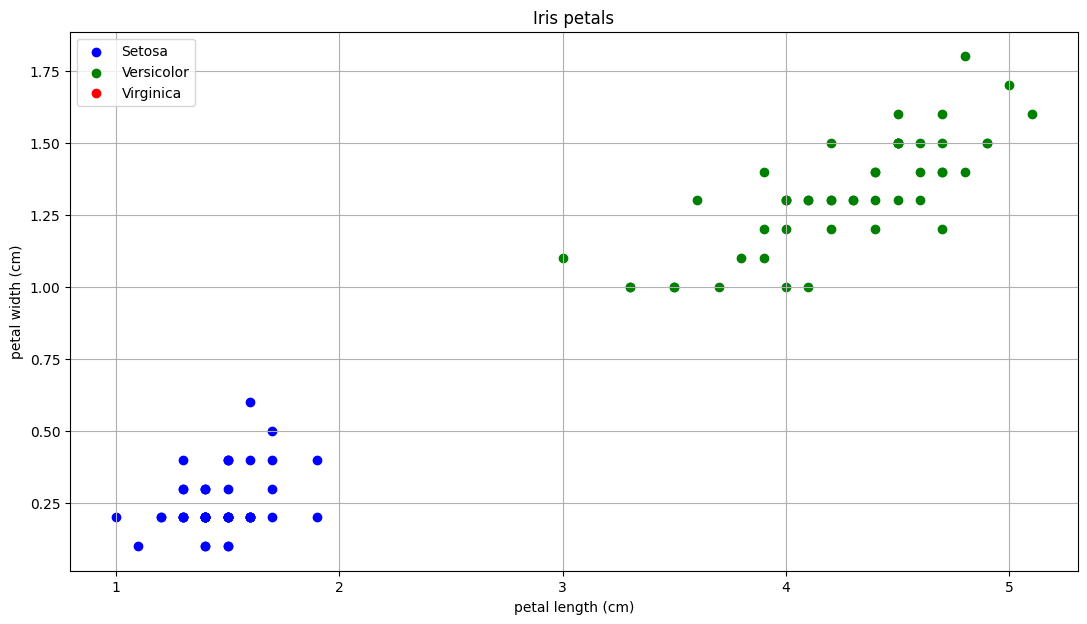

In [569]:
import matplotlib.pyplot as plt

setosa = iris[iris.species == "setosa"]
versicolor = iris[iris.species=='versicolor']
virginica = iris[iris.species=='virginica']

fig, ax = plt.subplots()
fig.set_size_inches(13, 7) # adjusting the length and width of plot

# lables and scatter points
ax.scatter(setosa['petal length (cm)'], setosa['petal width (cm)'], label="Setosa", facecolor="blue")
ax.scatter(versicolor['petal length (cm)'], versicolor['petal width (cm)'], label="Versicolor", facecolor="green")
ax.scatter(virginica['petal length (cm)'], virginica['petal width (cm)'], label="Virginica", facecolor="red")


ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.grid()
ax.set_title("Iris petals")
ax.legend()

In [570]:
#ci sono 4 features + 1 per il peso zero
w = np.full((4+1),fill_value=0.1,dtype=np.float64)

def percepton(x,w):
    z = sum(x*w)
    if z>0: return 1
    else: return -1
    

Training

In [571]:
iris_train = iris.head(80).copy()
iris_test = iris.tail(20).copy()

eta = 0.5

for i in range(len(iris_train['target'])):
    x_i = np.concatenate( ([1],np.array(iris_train.iloc[i][:4])) )
    y_i = percepton(x_i,w)
    
    label = -1
    if iris_train.iloc[i]['target'] == 0:
        label = 1
    
    w = w + eta*(label-y_i)*x_i
w


array([1.1, 1.9999999999999991, 6.3, -9.300000000000002, -3.5],
      dtype=object)

In [572]:
#iris_test.assign(previsione = 0)
prev = []
successi = 0
for i in range(len(iris_test['target'])):
    x_i = np.concatenate( ([1],np.array(iris_test.iloc[i][:4])) )
    prev.append((percepton(x_i,w), iris_test.iloc[i]['target']))
    
    if prev[i][0] == 1 and prev[i][1] == 0:
        successi +=1
    if prev[i][0] == -1 and prev[i][1] == 1:
        successi += 1
print("Succcessi:",successi,"Fail:",len(iris_test['target'])-successi)
iris_test

Succcessi: 20 Fail: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
80,4.9,2.4,3.3,1.0,1.0,versicolor
81,5.4,3.0,4.5,1.5,1.0,versicolor
82,6.2,2.2,4.5,1.5,1.0,versicolor
83,5.8,2.7,4.1,1.0,1.0,versicolor
84,4.8,3.0,1.4,0.1,0.0,setosa
85,4.4,2.9,1.4,0.2,0.0,setosa
86,5.2,3.4,1.4,0.2,0.0,setosa
87,5.2,3.5,1.5,0.2,0.0,setosa
88,6.1,2.9,4.7,1.4,1.0,versicolor
89,5.6,2.9,3.6,1.3,1.0,versicolor


One vs All

In [573]:
iris = iris_row.sample(frac=1).copy().reset_index(drop=True) 
iris_train = iris.head(115).copy()
iris_test = iris.tail(35).copy()

eta = 0.5


In [574]:
def train(dataset,classe,eta):
    w = np.full((4+1),fill_value=0.1,dtype=np.float64)
    for i in range(len(dataset['target'])):
        x_i = np.concatenate( ([1],np.array(dataset.iloc[i][:4])) )
        y_i = percepton(x_i,w)
        
        label = -1
        if iris_train.iloc[i]['target'] == classe:
            label = 1
        
        w = w + eta*(label-y_i)*x_i
    return w

p1 = train(iris_train, 0, eta)
p2 = train(iris_train, 1, eta)
p3 = train(iris_train, 2, eta)

In [575]:
def test(dataset,classificator,classe):
    successi = 0
    print("Classificatore",classe)
    for i in range(len(dataset['target'])):
        x_i = np.concatenate( ([1],np.array(dataset.iloc[i][:4])) )
        prev = percepton(x_i,classificator)
        
        if prev == 1 and iris_test.iloc[i]['target'] == classe:
            successi +=1
        if prev == -1 and iris_test.iloc[i]['target'] != classe:
            successi += 1
    print("Succcessi:",successi,"Fail:",len(iris_test['target'])-successi)

test(iris_test,p1,0)  
test(iris_test,p2,1)
test(iris_test,p3,2) 

Classificatore 0
Succcessi: 35 Fail: 0
Classificatore 1
Succcessi: 23 Fail: 12
Classificatore 2
Succcessi: 23 Fail: 12
